# 02 - Classical models: baseline, Logistic Regression, Random Forest

## How to reproduce

From the repository root (Python 3.11, uv installed):

```sh
uv sync --locked
uv run python -m weapon_detection.ml.classical   # full run, test used once
uv run jupyter nbconvert --to notebook --execute --inplace notebooks/02_classical_models.ipynb
```

The full training + single test evaluation was done by `weapon_detection/ml/classical.py`. This notebook re-runs the TUNING on train/validation only to show how settings were chosen, and then LOADS the saved test results - it does not evaluate the test set again.
The measured runtime is printed in the last cell.

**Seed.**

In [1]:
# Fixed seed for everything random in this notebook (the modules use SEED = 42 too).
import random
import time

import numpy as np
import pandas as pd
from IPython.display import Image, display

from weapon_detection.ml.common import OUTPUT_DIR, SEED

random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.width", 200)
notebook_start = time.perf_counter()
print("SEED =", SEED)

SEED = 42


**Step 1 - Load features and labels.** Features are joined to the manifest by image path, never by row order.

In [2]:
from weapon_detection.ml.features import load_features

manifest = pd.read_csv(OUTPUT_DIR / 'manifest.csv')
handcrafted, hog, names = load_features(manifest)
X = {'handcrafted': handcrafted, 'handcrafted_hog': np.hstack([handcrafted, hog])}
y = manifest['firearm_present'].to_numpy()
split = manifest['split'].to_numpy()
print({s: int((split == s).sum()) for s in ['train', 'val', 'test']})

{'train': 7583, 'val': 921, 'test': 921}


**Step 2 - Pre-processing inside a Pipeline.** The StandardScaler is a step of the pipeline, so `fit()` on the training rows is the only place it learns a mean and standard deviation. Trees do not need scaling.

In [3]:
from weapon_detection.ml.classical import make_pipeline

print(make_pipeline('baseline', {}))
print(make_pipeline('logreg', {'C': 0.01}))
print(make_pipeline('random_forest', {'max_depth': 10, 'min_samples_leaf': 1}))

Pipeline(steps=[('model', DummyClassifier(strategy='most_frequent'))])
Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 LogisticRegression(C=0.01, class_weight='balanced',
                                    max_iter=2000, random_state=42))])
Pipeline(steps=[('model',
                 RandomForestClassifier(class_weight='balanced_subsample',
                                        max_depth=10, n_estimators=300,
                                        n_jobs=-1, random_state=42))])


**Step 3 - Training and tuning on train/validation only.** For each grid value we fit on train and score macro-F1 on validation. Then we pick the decision threshold on the validation scores. (The Random Forest on HOG takes ~2 minutes and is tuned in classical.py; here we show the three faster models.) We check that we get the same settings that were saved before the test evaluation.

In [4]:
import json

from weapon_detection.ml.classical import fit_and_choose

saved = json.loads((OUTPUT_DIR / 'chosen_settings.json').read_text())
for model, feature_set in [('logreg', 'handcrafted'), ('random_forest', 'handcrafted'),
                           ('logreg', 'handcrafted_hog')]:
    pipeline, chosen = fit_and_choose(model, X[feature_set], y, split)
    key = f'{model}_{feature_set}'
    display(pd.DataFrame(chosen['tuning_log']))
    print(key, 'params', chosen['params'], 'threshold', chosen['threshold'])
    assert chosen['params'] == saved[key]['params']
    assert chosen['threshold'] == saved[key]['threshold']

  logreg {'C': 0.001}: val macro-F1 0.4941 (0.0s)
  logreg {'C': 0.01}: val macro-F1 0.5113 (0.1s)
  logreg {'C': 0.1}: val macro-F1 0.5207 (0.1s)


  logreg {'C': 1.0}: val macro-F1 0.5156 (0.1s)


,params,val_macro_f1_at_0.5,fit_s
0,{'C': 0.001},0.494099,0.031250
1,{'C': 0.01},0.511251,0.057313
2,{'C': 0.1},0.520719,0.066604
3,{'C': 1.0},0.515603,0.105418


logreg_handcrafted params {'C': 0.1} threshold 0.32


  random_forest {'max_depth': 10, 'min_samples_leaf': 1}: val macro-F1 0.6561 (2.4s)


  random_forest {'max_depth': 10, 'min_samples_leaf': 3}: val macro-F1 0.6460 (2.8s)


... (8 outputs left out)

  logreg {'C': 0.1}: val macro-F1 0.6466 (4.1s)


  logreg {'C': 1.0}: val macro-F1 0.6362 (6.3s)


,params,val_macro_f1_at_0.5,fit_s
0,{'C': 0.001},0.660356,1.189547
1,{'C': 0.01},0.650648,2.246215
2,{'C': 0.1},0.646632,4.130526
3,{'C': 1.0},0.636154,6.254740


logreg_handcrafted_hog params {'C': 0.001} threshold 0.47


**Step 4 - Test results (loaded, not recomputed).** The test split was evaluated exactly once by classical.py after the settings above were saved. The baseline shows accuracy next to macro-F1: it never predicts 'no firearm'.

In [5]:
metrics = pd.read_csv(OUTPUT_DIR / 'results' / 'classical_metrics.csv')
columns = ['model', 'feature_set', 'split', 'threshold', 'precision', 'recall',
           'f1', 'accuracy', 'macro_f1', 'neg_recall', 'roc_auc']
metrics[columns]

,model,feature_set,split,threshold,precision,recall,f1,accuracy,macro_f1,neg_recall,roc_auc
0,baseline,n/a (ignores input),val,NaN,0.9023,1.0000,0.9486,0.9023,0.4743,0.0000,0.5000
1,baseline,n/a (ignores input),test,NaN,0.9023,1.0000,0.9486,0.9023,0.4743,0.0000,0.5000
2,logreg,handcrafted,val,0.32,0.9300,0.8797,0.9041,0.8317,0.6076,0.3889,0.6621
3,logreg,handcrafted,test,0.32,0.9216,0.9194,0.9205,0.8567,0.5976,0.2778,0.6371
4,logreg,handcrafted_hog,val,0.47,0.9409,0.9194,0.9300,0.8751,0.6761,0.4667,0.7732
5,logreg,handcrafted_hog,test,0.47,0.9335,0.8953,0.9140,0.8480,0.6299,0.4111,0.7449
6,random_forest,handcrafted,val,0.49,0.9362,0.9182,0.9271,0.8697,0.6574,0.4222,0.7563
7,random_forest,handcrafted,test,0.49,0.9290,0.9290,0.9290,0.8719,0.6367,0.3444,0.7257
8,random_forest,handcrafted_hog,val,0.76,0.9366,0.9422,0.9394,0.8903,0.6811,0.4111,0.8021
9,random_forest,handcrafted_hog,test,0.76,0.9344,0.9434,0.9389,0.8893,0.6729,0.3889,0.7893


**Step 5 - Confusion matrices, ROC and PR curves on test.**

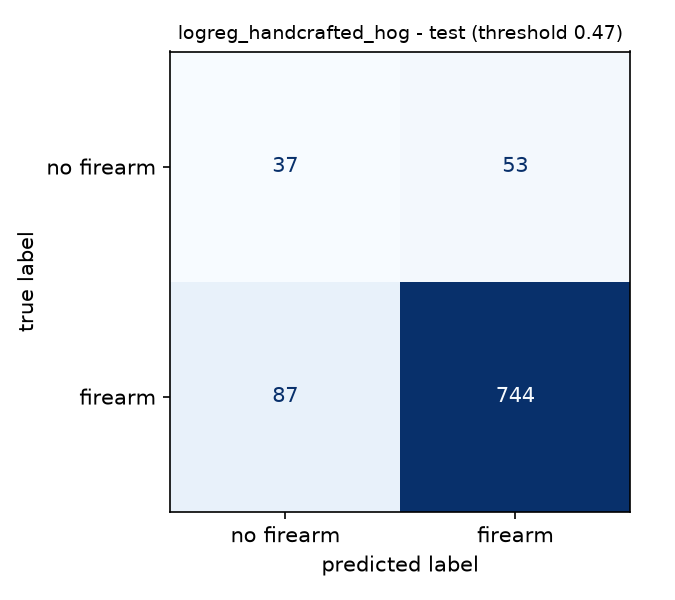

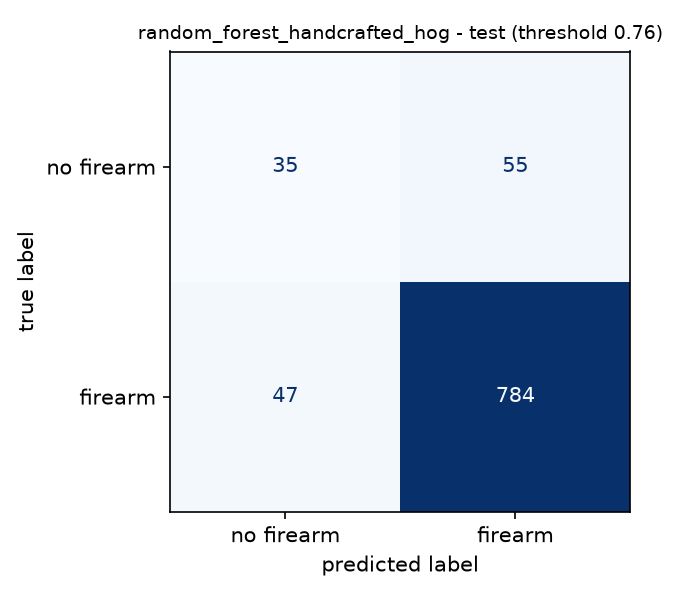

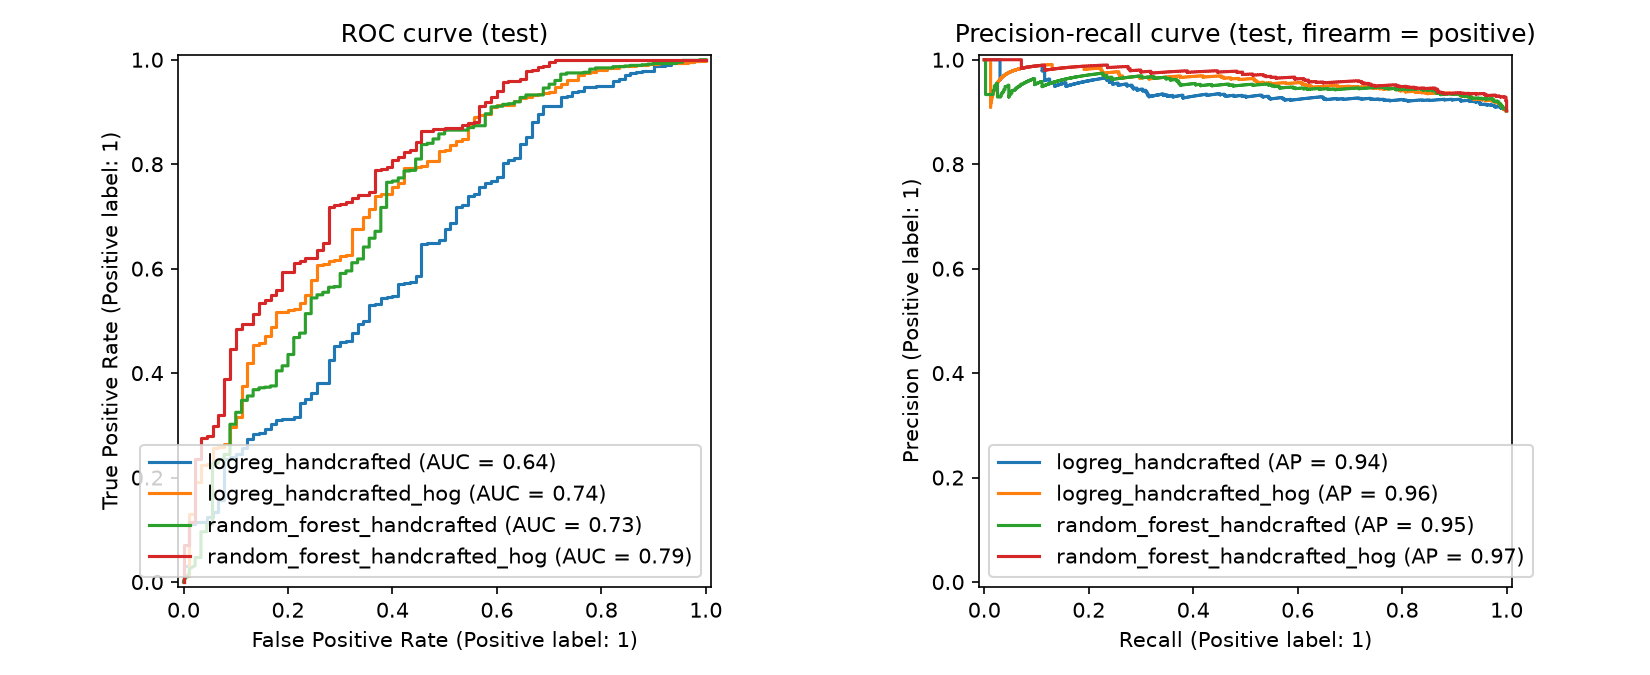

In [6]:
names = ['confusion_logreg_handcrafted_hog_test',
         'confusion_random_forest_handcrafted_hog_test', 'roc_pr_test']
for name in names:
    display(Image(filename=str(OUTPUT_DIR / 'figures' / f'{name}.png'), width=650))

**Step 6 - What the models use.** Logistic Regression coefficients (scaled features) and Random Forest impurity importance.

In [7]:
display(pd.read_csv(OUTPUT_DIR / 'results' / 'lr_coefficients_handcrafted_hog.csv'))
pd.read_csv(OUTPUT_DIR / 'results' / 'rf_importance.csv')

,feature,coefficient
0,histogram_entropy,-0.1565
1,mean_red,-0.1153
2,laplacian_sharpness,0.1122
3,dark_fraction,0.1080
4,edge_density,0.0726
5,mean_saturation,0.0593
6,mean_brightness,-0.0501
7,contrast_std,0.0345
8,mean_blue,-0.0278
9,mean_green,-0.0197


,feature_set,feature,importance
0,handcrafted,mean_brightness,0.0591
1,handcrafted,contrast_std,0.0884
2,handcrafted,edge_density,0.1313
3,handcrafted,mean_blue,0.0583
4,handcrafted,mean_green,0.0592
5,handcrafted,mean_red,0.1386
6,handcrafted,mean_saturation,0.1902
7,handcrafted,laplacian_sharpness,0.1063
8,handcrafted,dark_fraction,0.0803
9,handcrafted,histogram_entropy,0.0883


**Step 7 - Error analysis data.** The most confident wrong predictions on test. The `my_explanation` column is for me to fill in.

,image,error,true_label,score,classes_in_image,firearm_box_area_fraction,brightness,my_explanation
0,datasets/raw/weapon_detection_extracted/train/...,false_positive,0,0.9447,Knife,0.0000,242.3,NaN
1,datasets/raw/weapon_detection_extracted/train/...,false_positive,0,0.9368,Knife,0.0000,137.8,NaN
2,datasets/raw/weapon_detection_extracted/valid/...,false_positive,0,0.9122,Knife,0.0000,83.4,NaN
3,datasets/raw/weapon_detection_extracted/train/...,false_positive,0,0.9049,Knife,0.0000,72.8,NaN
4,datasets/raw/weapon_detection_extracted/valid/...,false_positive,0,0.9038,Knife,0.0000,145.0,NaN
5,datasets/raw/weapon_detection_extracted/train/...,false_negative,1,0.6156,Pistol,0.0221,129.7,NaN
6,datasets/raw/weapon_detection_extracted/train/...,false_negative,1,0.6659,Gun;Gun;Gun,0.0241,130.8,NaN
7,datasets/raw/weapon_detection_extracted/test/i...,false_negative,1,0.6719,Gun,0.0256,176.2,NaN
8,datasets/raw/weapon_detection_extracted/train/...,false_negative,1,0.6819,Gun,0.0953,150.1,NaN
9,datasets/raw/weapon_detection_extracted/train/...,false_negative,1,0.6920,Pistol,0.1702,122.1,NaN


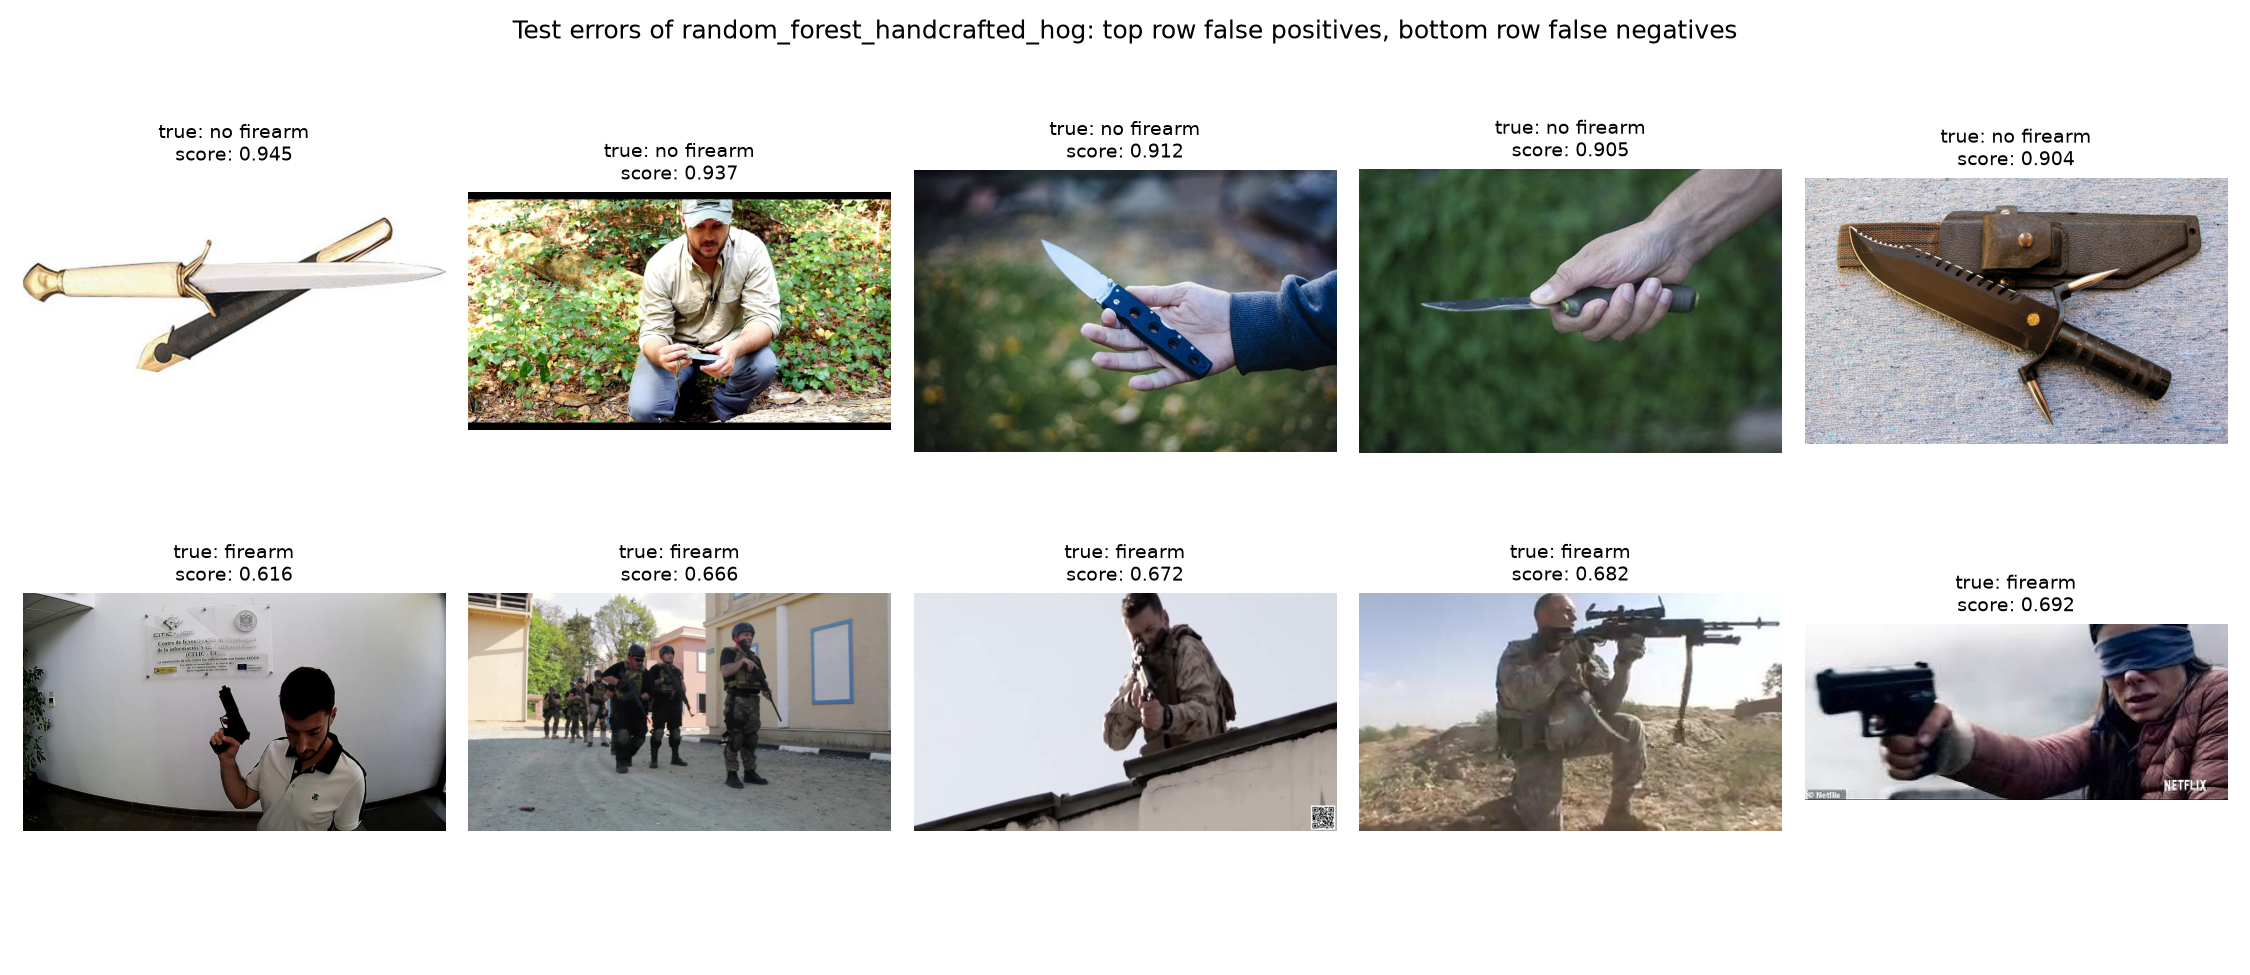

In [8]:
display(pd.read_csv(OUTPUT_DIR / 'error_analysis.csv'))
Image(filename=str(OUTPUT_DIR / 'figures' / 'error_analysis_grid.png'), width=900)

**Runtime.**

In [9]:
# Measured runtime of this notebook on the machine that executed it.
print(f"Notebook runtime: {time.perf_counter() - notebook_start:.0f} seconds")

Notebook runtime: 37 seconds
